Saving ENB2012_data.csv to ENB2012_data.csv
Dataset Shape: (768, 10)


,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


Index(['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'Y1', 'Y2'], dtype='object')
LINEAR REGRESSION
MAE : 2.182
RMSE: 3.025
R2  : 0.912

BAYESIAN LINEAR REGRESSION
MAE : 2.186
RMSE: 3.03
R2  : 0.912
Average Uncertainty: 2.927


,Actual Heating Load,Predicted Heating Load,Uncertainty,Lower 95%,Upper 95%,Absolute Error
0,16.47,18.971099,2.931751,13.224866,24.717332,2.501099
1,13.17,14.040994,2.920605,8.316608,19.765379,0.870994
2,32.82,31.413212,2.938572,25.653611,37.172813,1.406788
3,41.32,35.868802,2.921890,30.141898,41.595706,5.451198
4,16.69,15.386389,2.917185,9.668706,21.104071,1.303611
5,23.80,28.588956,2.925579,22.854822,34.323090,4.788956
6,24.31,25.126804,2.933079,19.377970,30.875638,0.816804
7,28.67,28.180311,2.935450,22.426830,33.933793,0.489689
8,19.52,17.805097,2.928557,12.065126,23.545069,1.714903
9,28.07,27.613199,2.922393,21.885309,33.341090,0.456801


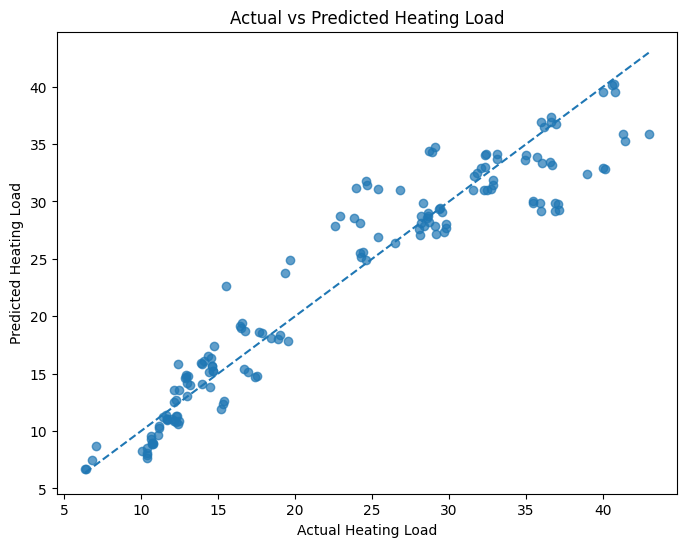

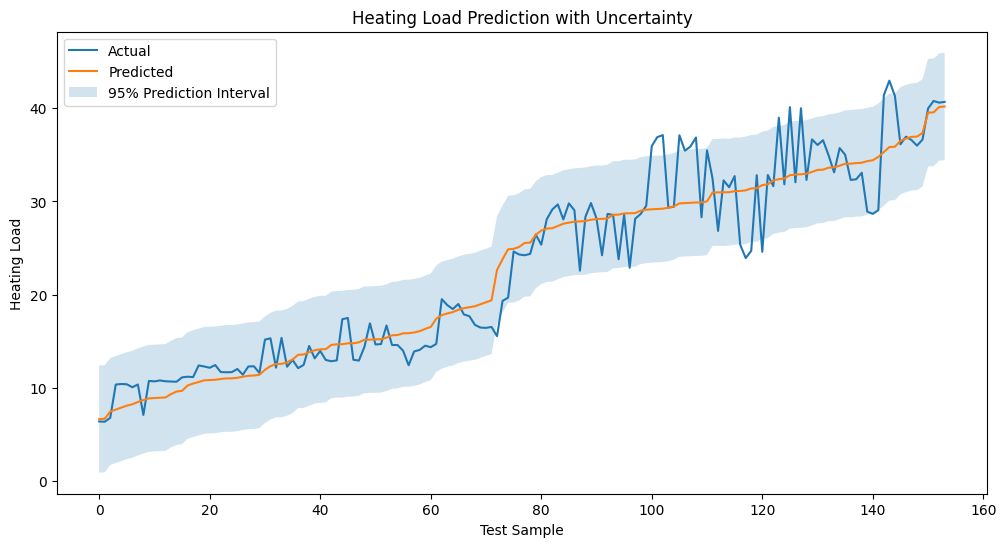


NEW BUILDING PREDICTION
Predicted Heating Load: 17.769
Uncertainty: ± 3.218
95% Prediction Interval: 11.462 to 24.076


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, BayesianRidge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


uploaded = files.upload()

file_name = next(iter(uploaded))

if file_name.lower().endswith(".csv"):
    df = pd.read_csv(file_name)
elif file_name.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(file_name)
else:
    raise ValueError("Please upload a CSV or Excel file")


df.columns = [str(c).strip() for c in df.columns]

print("Dataset Shape:", df.shape)
display(df.head())
print(df.columns)


features = ["X1", "X2", "X3", "X4", "X5", "X6", "X7", "X8"]
target = "Y1"


for column in features + [target]:
    df[column] = pd.to_numeric(df[column], errors="coerce")


df = df.dropna(subset=features + [target])


X = df[features]
y = df[target]


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)


linear_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])


bayesian_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", BayesianRidge())
])


linear_model.fit(X_train, y_train)
bayesian_model.fit(X_train, y_train)


linear_prediction = linear_model.predict(X_test)

linear_mae = mean_absolute_error(y_test, linear_prediction)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_prediction))
linear_r2 = r2_score(y_test, linear_prediction)


bayesian_estimator = bayesian_model.named_steps["model"]
scaler = bayesian_model.named_steps["scaler"]

X_test_scaled = scaler.transform(X_test)

bayesian_prediction, bayesian_std = bayesian_estimator.predict(
    X_test_scaled,
    return_std=True
)


bayesian_mae = mean_absolute_error(y_test, bayesian_prediction)
bayesian_rmse = np.sqrt(
    mean_squared_error(y_test, bayesian_prediction)
)
bayesian_r2 = r2_score(y_test, bayesian_prediction)


lower_bound = bayesian_prediction - 1.96 * bayesian_std
upper_bound = bayesian_prediction + 1.96 * bayesian_std


results = pd.DataFrame({
    "Actual Heating Load": y_test.values,
    "Predicted Heating Load": bayesian_prediction,
    "Uncertainty": bayesian_std,
    "Lower 95%": lower_bound,
    "Upper 95%": upper_bound
})


results["Absolute Error"] = abs(
    results["Actual Heating Load"] -
    results["Predicted Heating Load"]
)


print("LINEAR REGRESSION")
print("MAE :", round(linear_mae, 3))
print("RMSE:", round(linear_rmse, 3))
print("R2  :", round(linear_r2, 3))


print("\nBAYESIAN LINEAR REGRESSION")
print("MAE :", round(bayesian_mae, 3))
print("RMSE:", round(bayesian_rmse, 3))
print("R2  :", round(bayesian_r2, 3))
print(
    "Average Uncertainty:",
    round(bayesian_std.mean(), 3)
)


display(results.head(10))


plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    bayesian_prediction,
    alpha=0.7
)

minimum = min(
    y_test.min(),
    bayesian_prediction.min()
)

maximum = max(
    y_test.max(),
    bayesian_prediction.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Heating Load")
plt.ylabel("Predicted Heating Load")
plt.title("Actual vs Predicted Heating Load")

plt.show()


sorted_results = results.sort_values(
    "Predicted Heating Load"
).reset_index(drop=True)

x = np.arange(len(sorted_results))


plt.figure(figsize=(12, 6))

plt.plot(
    x,
    sorted_results["Actual Heating Load"],
    label="Actual"
)

plt.plot(
    x,
    sorted_results["Predicted Heating Load"],
    label="Predicted"
)

plt.fill_between(
    x,
    sorted_results["Lower 95%"],
    sorted_results["Upper 95%"],
    alpha=0.2,
    label="95% Prediction Interval"
)

plt.xlabel("Test Sample")
plt.ylabel("Heating Load")
plt.title("Heating Load Prediction with Uncertainty")
plt.legend()

plt.show()


new_building = pd.DataFrame([{
    "X1": 0.80,
    "X2": 600,
    "X3": 300,
    "X4": 150,
    "X5": 3.5,
    "X6": 3,
    "X7": 0.25,
    "X8": 4
}])


new_building_scaled = scaler.transform(
    new_building[features]
)


new_prediction, new_uncertainty = bayesian_estimator.predict(
    new_building_scaled,
    return_std=True
)


new_lower = (
    new_prediction[0] -
    1.96 * new_uncertainty[0]
)

new_upper = (
    new_prediction[0] +
    1.96 * new_uncertainty[0]
)


print("\nNEW BUILDING PREDICTION")
print(
    "Predicted Heating Load:",
    round(new_prediction[0], 3)
)

print(
    "Uncertainty: ±",
    round(new_uncertainty[0], 3)
)

print(
    "95% Prediction Interval:",
    round(new_lower, 3),
    "to",
    round(new_upper, 3)
)